In [1]:
# ==========================================================
# 1. IMPORT LIBRARIES
# ==========================================================

import os
import re
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# ==========================================================
# 2. LOAD DATASET
# ==========================================================

file_path = os.path.join("data", "TMDB_all_movies.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

df.head()

Dataset loaded successfully!
Number of rows: 1253185
Number of columns: 30


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.100,382.0,Released,1988-10-21,0.0,73.0,0.0,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.4,10048.0,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.300,448.0,Released,1986-10-17,0.0,74.0,0.0,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.4,8879.0,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.919,2911.0,Released,1995-12-09,4257354.0,98.0,4000000.0,tt0113101,...,"Allison Anders, Alexandre Rockwell, Quentin Ta...","Rodrigo García, Andrzej Sekula, Guillermo Nava...","Allison Anders, Alexandre Rockwell, Robert Rod...","Quentin Tarantino, Lawrence Bender, Alexandre ...",Combustible Edison,6.7,117723.0,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.400,387.0,Released,1993-10-15,12136938.0,110.0,21000000.0,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Lloyd Segan, Marilyn Vance",Alan Silvestri,6.6,21402.0,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R
4,8,Life in Loops (A Megacities RMX),7.300,34.0,Released,2006-01-01,0.0,80.0,42000.0,tt0825671,...,Timo Novotny,Wolfgang Thaler,"Michael Glawogger, Timo Novotny","Ulrich Gehmacher, Timo Novotny",NaN,8.1,285.0,/7ln81BRnPR2wqxuITZxEciCe1lc.jpg,megacities,NaN


In [4]:
# ==========================================================
# 3. UNDERSTAND THE DATASET
# ==========================================================

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (1253185, 30)

Column Names:
['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'budget', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'cast', 'director', 'director_of_photography', 'writers', 'producers', 'music_composer', 'imdb_rating', 'imdb_votes', 'poster_path', 'keywords', 'certification_us']

Data Types:
id                           int64
title                          str
vote_average               float64
vote_count                 float64
status                         str
release_date                   str
revenue                    float64
runtime                    float64
budget                     float64
imdb_id                        str
original_language              str
original_title                 str
overview                       str
popularity                 float64
tagline            

In [5]:
# ==========================================================
# 4. DATA CLEANING
# ==========================================================

# Remove movies without a title
df = df.dropna(subset=["title"])

# Remove duplicate movies
if "id" in df.columns:
    df = df.drop_duplicates(subset="id")
else:
    df = df.drop_duplicates(subset="title")

# Reset index
df = df.reset_index(drop=True)

# Create release year
if "release_date" in df.columns:
    df["release_year"] = pd.to_datetime(
        df["release_date"],
        errors="coerce"
    ).dt.year

# Fill missing text values
text_columns = [
    "overview",
    "genres",
    "keywords",
    "tagline",
    "cast",
    "director"
]

for column in text_columns:
    if column in df.columns:
        df[column] = df[column].fillna("")

print("Cleaning completed!")
print("Cleaned dataset shape:", df.shape)


Cleaning completed!
Cleaned dataset shape: (1253171, 31)


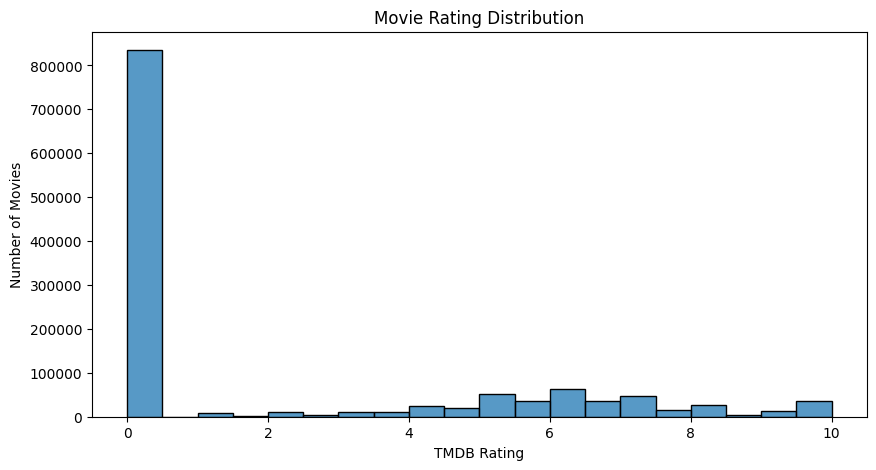

In [6]:
# ==========================================================
# 5. EXPLORATORY DATA ANALYSIS
# ==========================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    df["vote_average"].dropna(),
    bins=20
)

plt.title("Movie Rating Distribution")
plt.xlabel("TMDB Rating")
plt.ylabel("Number of Movies")

plt.show()

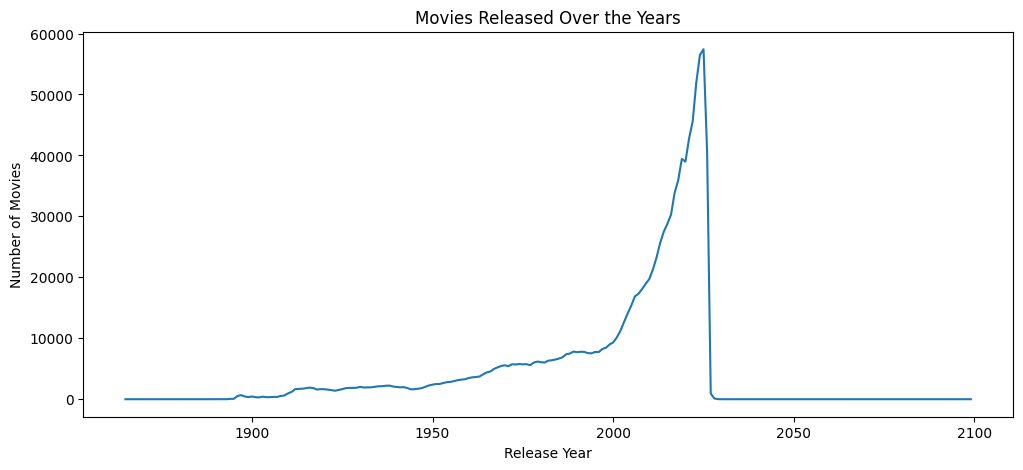

In [7]:
if "release_year" in df.columns:

    yearly_movies = df["release_year"].value_counts().sort_index()

    plt.figure(figsize=(12, 5))

    plt.plot(
        yearly_movies.index,
        yearly_movies.values
    )

    plt.title("Movies Released Over the Years")
    plt.xlabel("Release Year")
    plt.ylabel("Number of Movies")

    plt.show()

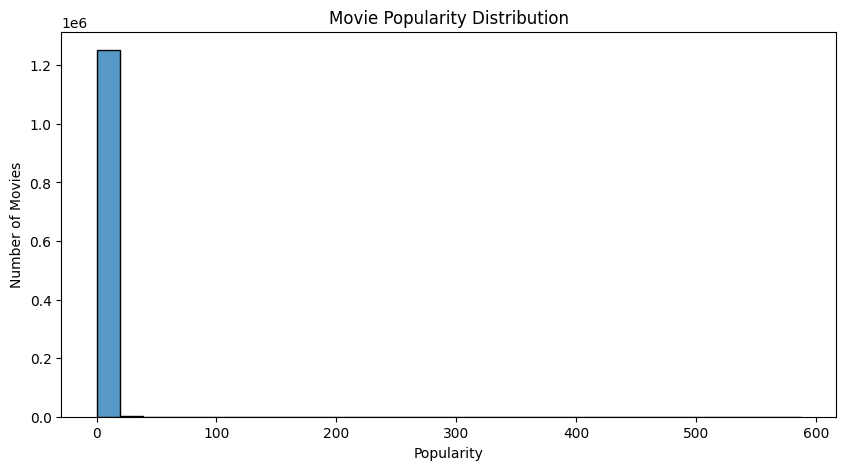

In [8]:
if "popularity" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["popularity"].dropna(),
        bins=30
    )

    plt.title("Movie Popularity Distribution")
    plt.xlabel("Popularity")
    plt.ylabel("Number of Movies")

    plt.show()

In [9]:
# ==========================================================
# 6. FEATURE ENGINEERING
# ==========================================================

def get_col_str(df_in, col):
    if col in df_in.columns:
        return df_in[col].astype(str)
    return ""

df["combined_metadata"] = (
    get_col_str(df, "overview") + " " +
    get_col_str(df, "genres") + " " +
    get_col_str(df, "keywords") + " " +
    get_col_str(df, "tagline") + " " +
    get_col_str(df, "cast").str.replace("|", " ", regex=False) + " " +
    get_col_str(df, "director").str.replace("|", " ", regex=False)
)

df[["title", "combined_metadata"]].head()

,title,combined_metadata
0,Ariel,A Finnish man goes to the city to find a job a...
1,Shadows in Paradise,"Nikander, a rubbish collector and would-be ent..."
2,Four Rooms,It's Ted the Bellhop's first night on the job....
3,Judgment Night,"Four young friends, while taking a shortcut en..."
4,Life in Loops (A Megacities RMX),Timo Novotny labels his new project an experim...


In [10]:
# ==========================================================
# 7. TEXT PREPROCESSING
# ==========================================================

def clean_text(text):

    text = str(text).lower()

    # Remove special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["processed_metadata"] = df["combined_metadata"].apply(clean_text)

df[["title", "processed_metadata"]].head()

,title,processed_metadata
0,Ariel,a finnish man goes to the city to find a job a...
1,Shadows in Paradise,nikander a rubbish collector and would be entr...
2,Four Rooms,it s ted the bellhop s first night on the job ...
3,Judgment Night,four young friends while taking a shortcut en ...
4,Life in Loops (A Megacities RMX),timo novotny labels his new project an experim...


In [11]:
# ==========================================================
# 8. TF-IDF VECTORIZATION
# ==========================================================

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

tfidf_matrix = tfidf.fit_transform(
    df["processed_metadata"]
)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (1253171, 10000)


In [12]:
# ==========================================================
# 9. COSINE SIMILARITY
# ==========================================================

def get_movie_recommendations(movie_title, top_n=5):

    matches = df[
        df["title"].str.lower() == movie_title.lower()
    ]

    if matches.empty:

        matches = df[
            df["title"].str.contains(
                re.escape(movie_title),
                case=False,
                na=False
            )
        ]

    if matches.empty:

        print(f"Movie '{movie_title}' was not found.")
        return None

    movie_index = matches.index[0]

    similarity_scores = cosine_similarity(
        tfidf_matrix[movie_index],
        tfidf_matrix
    ).flatten()

    similar_movies = similarity_scores.argsort()[::-1]

    recommended_indices = [
        index
        for index in similar_movies
        if index != movie_index
    ][:top_n]

    recommendations = df.iloc[
        recommended_indices
    ][
        ["title", "genres", "vote_average", "release_year"]
    ].copy()

    recommendations["similarity_score"] = np.round(
        similarity_scores[recommended_indices],
        3
    )

    return recommendations

In [13]:
# ==========================================================
# 10. TEST RECOMMENDATION
# ==========================================================

get_movie_recommendations(
    "Four Rooms",
    5
)

,title,genres,vote_average,release_year,similarity_score
1021377,Pulp Fiction: The Facts,Documentary,0.0,2002.0,0.289
852599,409 – Please Make Up My Room,Drama,0.0,2023.0,0.277
840196,Karma,"Comedy, Drama",0.0,NaN,0.275
467109,Quattro,,4.0,1999.0,0.269
1001188,The Still Alarm,Drama,0.0,1984.0,0.254


In [14]:
# ==========================================================
# 11. MOVIE DETAILS SEARCH
# ==========================================================

def search_movie_details(movie_name):

    if not movie_name or not str(movie_name).strip():
        print("Please enter a valid movie title.")
        return

    matches = df[
        df["title"].str.lower() == movie_name.lower()
    ]

    if matches.empty:

        matches = df[
            df["title"].str.contains(
                re.escape(movie_name),
                case=False,
                na=False
            )
        ]

    if matches.empty:

        print(f"No movie found matching '{movie_name}'.")
        return

    movie = matches.iloc[0]

    print("=" * 60)
    print("MOVIE DETAILS")
    print("=" * 60)

    print(f"Title: {movie['title']}")

    # Rating
    print(
        f"TMDB Rating: {movie['vote_average']:.1f}/10"
    )

    if (
        "imdb_rating" in df.columns
        and pd.notna(movie["imdb_rating"])
    ):
        print(
            f"IMDb Rating: {movie['imdb_rating']:.1f}/10"
        )

    print(f"Genres: {movie['genres']}")
    
    release_yr = (
        int(movie['release_year'])
        if "release_year" in df.columns and pd.notna(movie['release_year'])
        else "N/A"
    )
    print(f"Release Year: {release_yr}")

    if "original_language" in df.columns and pd.notna(movie["original_language"]):
        print(
            f"Language: {str(movie['original_language']).upper()}"
        )

    if "director" in df.columns and pd.notna(movie["director"]):
        print(f"Director: {movie['director']}")

    if "cast" in df.columns and pd.notna(movie["cast"]):
        cast = str(movie["cast"]).split("|")[:5]
        print(f"Cast: {', '.join(cast)}")

    print("-" * 60)

    print("Overview:")
    print(movie["overview"])

    print("=" * 60)

In [15]:
# ==========================================================
# 12. GENRE SEARCH
# ==========================================================

def search_by_genres(genres, max_results=10):

    result = df.copy()

    # Convert genres to lowercase
    result["genre_text"] = (
        result["genres"]
        .fillna("")
        .str.lower()
    )

    # Make sure every requested genre exists
    for genre in genres:

        result = result[
            result["genre_text"].str.contains(
                genre.lower(),
                na=False
            )
        ]

    # Sort results
    if "popularity" in result.columns:

        result = result.sort_values(
            "popularity",
            ascending=False
        )

    return result[
        [
            "title",
            "genres",
            "vote_average",
            "release_year"
        ]
    ].head(max_results)


search_by_genres(
    ["comedy", "romance"],
    10
)

In [16]:
# ==========================================================
# 13. LANGUAGE + GENRE SEARCH
# ==========================================================

LANGUAGE_MAP = {
    "english": "en",
    "hindi": "hi",
    "korean": "ko",
    "japanese": "ja",
    "french": "fr",
    "spanish": "es",
    "german": "de",
    "italian": "it",
    "chinese": "zh",
    "tamil": "ta",
    "telugu": "te"
}

In [17]:
def search_movies(genres=None, language=None,
                  min_rating=0, year=None,
                  max_results=10):

    result = df.copy()

    # Language
    if language and "original_language" in result.columns:

        result = result[
            result["original_language"].str.lower()
            == language.lower()
        ]

    # Genres
    if genres:

        result["genre_text"] = (
            result["genres"]
            .fillna("")
            .str.lower()
        )

        for genre in genres:

            result = result[
                result["genre_text"].str.contains(
                    genre.lower(),
                    na=False
                )
            ]

    # Rating
    if min_rating > 0:

        result = result[
            result["vote_average"] >= min_rating
        ]

    # Year
    if year:

        result = result[
            result["release_year"] == year
        ]

    # Sort
    if "popularity" in result.columns:

        result = result.sort_values(
            "popularity",
            ascending=False
        )

    return result[
        [
            "title",
            "genres",
            "vote_average",
            "release_year"
        ]
    ].head(max_results)



search_movies(
    genres=["romance", "comedy"],
    language="hi"
)

,title,genres,vote_average,release_year
11735,Dilwale Dulhania Le Jayenge,"Comedy, Drama, Romance",8.505,1995.0
1071260,Don't Be Shy!,"Romance, Comedy",7.000,2026.0
646298,Zara Hatke Zara Bachke,"Comedy, Drama, Romance",5.700,2023.0
972869,Cocktail 2,"Romance, Comedy",5.800,2026.0
929472,Pati Patni Aur Woh Do,"Comedy, Drama, Romance",6.000,2026.0
43510,Utt Pataang,"Comedy, Romance",5.000,2011.0
24908,Hello Brother,"Comedy, Romance",5.600,1999.0
1149183,Prem Keetanu,"Comedy, Romance",0.000,2026.0
346524,Love per Square Foot,"Comedy, Romance",6.700,2018.0
920349,Hai Jawani Toh Ishq Hona Hai,"Romance, Comedy",5.300,2026.0


In [18]:
# ==========================================================
# 14. SIMPLE NATURAL LANGUAGE SEARCH
# ==========================================================

GENRE_KEYWORDS = {

    "romcom": ["romance", "comedy"],
    "romantic": ["romance"],
    "comedy": ["comedy"],
    "thriller": ["thriller"],
    "action": ["action"],
    "horror": ["horror"],
    "sci-fi": ["science fiction"],
    "scifi": ["science fiction"],
    "drama": ["drama"],
    "animation": ["animation"],
    "crime": ["crime"],
    "mystery": ["mystery"],
    "family": ["family"],
    "war": ["war"]
}

In [21]:
def movie_search_engine(query):

    if not query or not str(query).strip():
        print("Please enter a valid search query.")
        return None

    query = query.strip().lower()

    # ---------------------------------------
    # 1. Recommendation request
    # ---------------------------------------

    recommendation_match = re.search(
        r"(?:movies like|similar to|recommendations for)\s+(.+)",
        query
    )

    if recommendation_match:

        movie_name = recommendation_match.group(1).strip()

        print(
            f"\nRecommendations for: {movie_name}"
        )

        return get_movie_recommendations(
            movie_name,
            10
        )

    # ---------------------------------------
    # 2. Find genres
    # ---------------------------------------

    genres = []

    for keyword, genre_list in GENRE_KEYWORDS.items():

        if re.search(
            rf"\b{re.escape(keyword)}\b",
            query
        ):

            genres.extend(genre_list)

    genres = list(dict.fromkeys(genres))

    # ---------------------------------------
    # 3. Find language
    # ---------------------------------------

    language = None

    for language_name, language_code in LANGUAGE_MAP.items():

        if re.search(
            rf"\b{language_name}\b",
            query
        ):

            language = language_code
            break

    # ---------------------------------------
    # 4. Find year
    # ---------------------------------------

    year_match = re.search(
        r"\b(?:from|in|of|year)\s+(\d{4})\b",
        query
    )

    year = (
        int(year_match.group(1))
        if year_match
        else None
    )

    # ---------------------------------------
    # 5. Rating
    # ---------------------------------------

    min_rating = 0

    if (
        "highly rated" in query
        or "best" in query
        or "top rated" in query
    ):
        min_rating = 7

    # ---------------------------------------
    # 6. Filter request
    # ---------------------------------------

    if genres or language or year or min_rating:

        return search_movies(
            genres=genres,
            language=language,
            min_rating=min_rating,
            year=year,
            max_results=10
        )

    # ---------------------------------------
    # 7. Otherwise search movie details
    # ---------------------------------------

    return search_movie_details(query)

In [ ]:
# ==========================================================
# 16. INTERACTIVE MOVIE SEARCH
# ==========================================================

print("=" * 60)
print("        TMDB MOVIE RECOMMENDATION SYSTEM")
print("=" * 60)

print("""
You can search for:

1. A movie
   Example: Inception

2. Similar movies
   Example: movies like Inception

3. Genre
   Example: comedy movies

4. Multiple genres
   Example: romantic comedy movies

5. Language + genre
   Example: hindi romantic movies

6. Year
   Example: thriller movies from 2010

7. Rating
   Example: highly rated comedy movies

Type 'exit' to stop.
""")

while True:

    query = input("\nEnter your search: ")

    if query.lower() == "exit":
        print("Thank you for using the Movie Recommendation System!")
        break

    result = movie_search_engine(query)

    if isinstance(result, pd.DataFrame):

        if result.empty:

            print(
                "\nNo movies found for your search."
            )

        else:

            print(
                f"\nFound {len(result)} movies:\n"
            )

            display(result)

        TMDB MOVIE RECOMMENDATION SYSTEM

You can search for:

1. A movie
   Example: Inception

2. Similar movies
   Example: movies like Inception

3. Genre
   Example: comedy movies

4. Multiple genres
   Example: romantic comedy movies

5. Language + genre
   Example: hindi romantic movies

6. Year
   Example: thriller movies from 2010

7. Rating
   Example: highly rated comedy movies

Type 'exit' to stop.


Found 10 movies:



,title,genres,vote_average,release_year
153218,Loves of a French Pussycat,Comedy,4.200,1972.0
842130,Coyote vs. Acme,"Comedy, Adventure, Family",7.531,2026.0
961609,Runner,"Action, Comedy",8.273,2026.0
875435,Digger,"Comedy, Drama",7.400,2026.0
722686,The Love Hypothesis,"Romance, Comedy",8.043,2026.0
756606,Toy Story 5,"Animation, Family, Comedy, Adventure",8.318,2026.0
836853,The Hawk,"Action, Adventure, Comedy",8.400,2023.0
12171,Sex with Love,"Comedy, Romance",6.500,2003.0
19064,Cavegirl,Comedy,4.000,1985.0
1034145,Ice Cream Man,"Comedy, Horror, Thriller",4.807,2026.0
